In [2]:
# Phylogenetic Analysis
# This notebook performs a phylogenetic analysis using sequence data.
#11,443 sequences from the NCBI database are analyzed to construct a phylogenetic tree.

import squirrel
from Bio import SeqIO
import os
import networkx as nx
import pandas as pd
import hashlib
import re
import numpy as np
from datetime import datetime
from sklearn.linear_model import LinearRegression
from collections import defaultdict, Counter
from itertools import combinations
from urllib.parse import unquote
from Bio.SeqIO import parse
from typing import Iterable, List, Dict, Tuple, Any, Optional
import matplotlib.pyplot as plt

In [63]:
#prestep: split the fasta file into chunks of different sizes to try Nextclade (https://clades.nextstrain.org/) ,it shows 500 sequences with 20 CPU threads and mpox virus (lineage B.1) and export using general file format with seqName and clade is enough for our purpose.
input_file="data/sequence.fasta"
output_dir="chrunks"
chunk_size=1000

os.makedirs(output_dir, exist_ok=True)

records=list(SeqIO.parse(input_file, "fasta"))
total= len(records)
print(f"Total sequences: {total}")

for i in range(0, total, chunk_size):
    chunk_records= records[i:i+chunk_size]
    chunk_file= os.path.join(output_dir, f"chunk_{i//chunk_size + 1}.fasta")
    SeqIO.write(chunk_records, chunk_file, "fasta")
    print(f"Wrote {len(chunk_records)} sequences to {chunk_file}")

FileNotFoundError: [Errno 2] No such file or directory: 'data/sequence.fasta'

In [3]:
input_file="data/sequence.fasta"
output_dir="chrunks_50"
chunk_size=50

os.makedirs(output_dir, exist_ok=True)

records=list(SeqIO.parse(input_file, "fasta"))
total= len(records)
print(f"Total sequences: {total}")

for i in range(0, total, chunk_size):
    chunk_records= records[i:i+chunk_size]
    chunk_file= os.path.join(output_dir, f"chunk_{i//chunk_size + 1}.fasta")
    SeqIO.write(chunk_records, chunk_file, "fasta")
    print(f"Wrote {len(chunk_records)} sequences to {chunk_file}")

Total sequences: 11443
Wrote 50 sequences to chrunks_50\chunk_1.fasta
Wrote 50 sequences to chrunks_50\chunk_2.fasta
Wrote 50 sequences to chrunks_50\chunk_3.fasta
Wrote 50 sequences to chrunks_50\chunk_4.fasta
Wrote 50 sequences to chrunks_50\chunk_5.fasta
Wrote 50 sequences to chrunks_50\chunk_6.fasta
Wrote 50 sequences to chrunks_50\chunk_7.fasta
Wrote 50 sequences to chrunks_50\chunk_8.fasta
Wrote 50 sequences to chrunks_50\chunk_9.fasta
Wrote 50 sequences to chrunks_50\chunk_10.fasta
Wrote 50 sequences to chrunks_50\chunk_11.fasta
Wrote 50 sequences to chrunks_50\chunk_12.fasta
Wrote 50 sequences to chrunks_50\chunk_13.fasta
Wrote 50 sequences to chrunks_50\chunk_14.fasta
Wrote 50 sequences to chrunks_50\chunk_15.fasta
Wrote 50 sequences to chrunks_50\chunk_16.fasta
Wrote 50 sequences to chrunks_50\chunk_17.fasta
Wrote 50 sequences to chrunks_50\chunk_18.fasta
Wrote 50 sequences to chrunks_50\chunk_19.fasta
Wrote 50 sequences to chrunks_50\chunk_20.fasta
Wrote 50 sequences to chru

In [4]:
input_file="data/sequence.fasta"
output_dir="chrunks_500"
chunk_size=500

os.makedirs(output_dir, exist_ok=True)

records=list(SeqIO.parse(input_file, "fasta"))
total= len(records)
print(f"Total sequences: {total}")

for i in range(0, total, chunk_size):
    chunk_records= records[i:i+chunk_size]
    chunk_file= os.path.join(output_dir, f"chunk_{i//chunk_size + 1}.fasta")
    SeqIO.write(chunk_records, chunk_file, "fasta")
    print(f"Wrote {len(chunk_records)} sequences to {chunk_file}")

Total sequences: 11443
Wrote 500 sequences to chrunks_500\chunk_1.fasta
Wrote 500 sequences to chrunks_500\chunk_2.fasta
Wrote 500 sequences to chrunks_500\chunk_3.fasta
Wrote 500 sequences to chrunks_500\chunk_4.fasta
Wrote 500 sequences to chrunks_500\chunk_5.fasta
Wrote 500 sequences to chrunks_500\chunk_6.fasta
Wrote 500 sequences to chrunks_500\chunk_7.fasta
Wrote 500 sequences to chrunks_500\chunk_8.fasta
Wrote 500 sequences to chrunks_500\chunk_9.fasta
Wrote 500 sequences to chrunks_500\chunk_10.fasta
Wrote 500 sequences to chrunks_500\chunk_11.fasta
Wrote 500 sequences to chrunks_500\chunk_12.fasta
Wrote 500 sequences to chrunks_500\chunk_13.fasta
Wrote 500 sequences to chrunks_500\chunk_14.fasta
Wrote 500 sequences to chrunks_500\chunk_15.fasta
Wrote 500 sequences to chrunks_500\chunk_16.fasta
Wrote 500 sequences to chrunks_500\chunk_17.fasta
Wrote 500 sequences to chrunks_500\chunk_18.fasta
Wrote 500 sequences to chrunks_500\chunk_19.fasta
Wrote 500 sequences to chrunks_500\c

In [64]:
input_file="data/4.deduplicated_sequences.fasta"
output_dir="chrunks_100"
chunk_size=100

os.makedirs(output_dir, exist_ok=True)

records=list(SeqIO.parse(input_file, "fasta"))
total= len(records)
print(f"Total sequences: {total}")

for i in range(0, total, chunk_size):
    chunk_records= records[i:i+chunk_size]
    chunk_file= os.path.join(output_dir, f"chunk_{i//chunk_size + 1}.fasta")
    SeqIO.write(chunk_records, chunk_file, "fasta")
    print(f"Wrote {len(chunk_records)} sequences to {chunk_file}")

Total sequences: 14528
Wrote 100 sequences to chrunks_100\chunk_1.fasta
Wrote 100 sequences to chrunks_100\chunk_2.fasta
Wrote 100 sequences to chrunks_100\chunk_3.fasta
Wrote 100 sequences to chrunks_100\chunk_4.fasta
Wrote 100 sequences to chrunks_100\chunk_5.fasta
Wrote 100 sequences to chrunks_100\chunk_6.fasta
Wrote 100 sequences to chrunks_100\chunk_7.fasta
Wrote 100 sequences to chrunks_100\chunk_8.fasta
Wrote 100 sequences to chrunks_100\chunk_9.fasta
Wrote 100 sequences to chrunks_100\chunk_10.fasta
Wrote 100 sequences to chrunks_100\chunk_11.fasta
Wrote 100 sequences to chrunks_100\chunk_12.fasta
Wrote 100 sequences to chrunks_100\chunk_13.fasta
Wrote 100 sequences to chrunks_100\chunk_14.fasta
Wrote 100 sequences to chrunks_100\chunk_15.fasta
Wrote 100 sequences to chrunks_100\chunk_16.fasta
Wrote 100 sequences to chrunks_100\chunk_17.fasta
Wrote 100 sequences to chrunks_100\chunk_18.fasta
Wrote 100 sequences to chrunks_100\chunk_19.fasta
Wrote 100 sequences to chrunks_100\c

In [7]:
#step 1: merge all fasta files into one file

# List of input FASTA files
input_files = ["data/sequence.fasta", "data/gisaid_pox_2025_11_06_04_1.fasta", "data/gisaid_pox_2025_11_06_04_2.fasta"]

# Output merged FASTA file
output_file = "merged_sequences.fasta"

# Read and combine all sequences
all_records = []
for file in input_files:
    records = list(SeqIO.parse(file, "fasta"))
    all_records.extend(records)

# Write to a single merged FASTA file
SeqIO.write(all_records, output_file, "fasta")

print(f"✅ Merged {len(all_records)} sequences into {output_file}")


✅ Merged 20737 sequences into merged_sequences.fasta


In [9]:
##check the length of sequences and sequencing quality


# === File paths ===
input_fasta="data/merged_sequences.fasta"         # Input file name 
output_fasta="data/filtered_sequences.fasta"     # Output FASTA file
discarded_excel="data/discarded_sequences.xlsx"  # Output Excel file

# === Threshold for ambiguous bases ===
threshold=0.2 # 20%
threshold_length=30000  # Minimum length of sequences to consider
# === Containers for results ===
filtered_records=[]
discarded_records_length,discarded_records_quality=[],[]

# === Process each sequence ===
for record in SeqIO.parse(input_fasta, "fasta"):
    sequence = str(record.seq).upper()
    n_count= sequence.count('N')
    n_faction = n_count / len(sequence)
    
    if n_faction <= threshold and len(sequence) >= threshold_length:
        filtered_records.append(record)
    elif len(sequence) < threshold_length:
        discarded_records_length.append({
            'Sequence_ID': record.id,
            'Length': len(sequence),
            'N_Count': n_count,
            'N_Fraction': n_faction,
            "filtered_reason": "Length below threshold"
        })
    else:
        discarded_records_quality.append({
            'Sequence_ID': record.id,
            'Length': len(sequence),
            'N_Count': n_count,
            'N_Fraction': n_faction,
            "filtered_reason": "High N content"
        })
        
# === Save filtered sequences ===
SeqIO.write(filtered_records, output_fasta, "fasta")
# === Combine discarded records info ===
discarded_records = discarded_records_length + discarded_records_quality


# === Save discarded sequences info to Excel ===
df_discarded = pd.DataFrame(discarded_records)
df_discarded.to_excel(discarded_excel, index=False)


print(f"✅ Filtered sequences saved to: {output_fasta}")
print(f"📄 Discarded sequence report saved to: {discarded_excel}")


✅ Filtered sequences saved to: data/filtered_sequences.fasta
📄 Discarded sequence report saved to: data/discarded_sequences.xlsx


In [13]:
##check the duplicated sequences
def get_sequence_hash(sequence):
    """Return MD5 hash of a sequence string."""
    return hashlib.md5(sequence.encode()).hexdigest()


input_fasta="data/filtered_sequences.fasta"

# Dictionary to store hashes and their source
hash_dict = {}

# List to collect duplicate entries
duplicate_entries=[]

for record in SeqIO.parse(input_fasta, "fasta"):
    seq_str = str(record.seq).upper()
    seq_hash = get_sequence_hash(seq_str)
    if seq_hash in hash_dict:
        #Duplicate found
        duplicate_entries.append({
            "Sequence_ID": record.id,
            "Duplicate_of": hash_dict[seq_hash],
            "Hash": seq_hash
        })
    else:
        hash_dict[seq_hash] = record.id


# Save duplicates to Excel
if duplicate_entries:
    df = pd.DataFrame(duplicate_entries)
    df.to_excel("duplicate_sequences.xlsx", index=False)
    print("✅ Duplicate sequence summary saved to 'duplicate_sequences.xlsx'")
else:
    print("✅ No duplicate sequences found.")



✅ Duplicate sequence summary saved to 'duplicate_sequences.xlsx'


In [64]:


# Paths
input_file = "data/sequence_influenza.gff3"
output_file = "data/genbank_meta_sex_influenza.xlsx"

# Extract file name without extension
file_name = os.path.basename(input_file)

# Read GFF3 file, skipping comment lines
gff_data = pd.read_csv(
    input_file,
    sep="\t",
    comment="#",
    header=None,
    names=["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"]
)

# Filter for 'region' rows (top-level record metadata commonly stored here)
region_rows = gff_data[gff_data["type"] == "region"].copy()



def parse_attributes(attr_str: str) -> dict:
    """
    Parse a GFF3 attributes string into a dict.
    - Splits on ';'
    - Splits key/value on the first '='
    - Decodes percent-encoded values (per GFF3 spec)
    """
    attrs = {}
    if pd.isna(attr_str):
        return attrs
    for item in str(attr_str).split(";"):
        if not item:
            continue
        if "=" in item:
            key, val = item.split("=", 1)
            attrs[key] = unquote(val)
    return attrs


# Extract metadata
metadata = []
for _, row in region_rows.iterrows():
    attrs = parse_attributes(row["attributes"])
    # Robust fallbacks
    sample_name = attrs.get("isolate", attrs.get("strain", ""))  # isolate or stra
    collection_date = attrs.get("collection-date", attrs.get("collection_date", ""))  # either key
    # Prefer geo_loc_name, fallback to country
    geo_location = attrs.get("geo_loc_name", attrs.get("country", ""))
    # Prefer host, fallback to nat-host (some GFFs use 'nat-host')
    host = attrs.get("host", attrs.get("nat-host", ""))
    gender = attrs.get("gender", "")
    sex = attrs.get("sex", "")

    metadata.append({
        "File_Name": file_name,
        "Accession_ID": row["seqid"],
        "Sample_Name": sample_name,
        "Collection_Date": collection_date,
        "Geo_Location": geo_location,   # <-- added
        "Country": attrs.get("country", ""),  # keep country explicitly if present
        "Host": host,
        "Gender": gender,
        "Sex": sex
    })



# Convert to DataFrame and save to Excel
metadata_df = pd.DataFrame(metadata)
metadata_df.to_excel(output_file, index=False)

print(f"✅ Metadata extracted and saved to: {output_file}")



✅ Metadata extracted and saved to: data/genbank_meta_sex_influenza.xlsx


In [119]:
# remove duplicated sequences based on the duplicate_sequences.xlsx file
excel_file="data/duplicate_sequences.xlsx"
input_fasta="data/3.filtered_sequences.fasta"
output_fasta="data/4.deduplicated_sequences.fasta"
delete_list_file="data/deleted_sequences.txt"

# Read duplicate sequence IDs from Excel
df_duplicates=pd.read_excel(excel_file)

#dujge whether the seq ID is from GenBank or GISAID based on the ID pattern
def is_genbank(seq_id):
    return seq_id.endswith(".1") or seq_id.endswith(".2") or seq_id.endswith(".3") or seq_id.endswith(".4") or seq_id.endswith(".5")

#construct a graph to store the duplicate relationships
G=nx.Graph()
for _, row in df_duplicates.iterrows():
    if row['Same']==1:
        G.add_edge(str(row["Sequence_ID"]).strip(), str(row["Duplicate_of"]).strip())

# Find connected components (groups of duplicates)
connected_components=list(nx.connected_components(G))

# Create a set of sequence IDs to delete (keeping one from each group)
delete_ids=[]

for component in connected_components:
    # Keep one sequence, delete the rest
    component_list=list(component)
    gisaid_candidates=[seq_id for seq_id in component_list if not is_genbank(seq_id)]
    if gisaid_candidates:
        keep_id=gisaid_candidates[0]
    else:
        keep_id=component_list[0]
    for seq_id in component_list:
        if seq_id != keep_id:
            delete_ids.append(seq_id)
# Save deleted sequence IDs to a text file
with open(delete_list_file, "w") as f:
    for seq_id in delete_ids:
        f.write(f"{seq_id}\n")
    
print(f"duplicated sequence IDs saved to {delete_list_file}")

#filter the input FASTA file to remove duplicates
records= SeqIO.parse(input_fasta, "fasta")
delete_set=set(delete_ids)
filtered_records=[record for record in records if record.id not in delete_set]
SeqIO.write(filtered_records, output_fasta, "fasta")
print(f"deduplicated sequences saved to {output_fasta}")

duplicated sequence IDs saved to data/deleted_sequences.txt
deduplicated sequences saved to data/4.deduplicated_sequences.fasta


In [130]:
#save sequence id to a new excel
input_fasta="data/4.deduplicated_sequences.fasta"
records= SeqIO.parse(input_fasta, "fasta")
sequence_ids=[record.id.split("|")[0].split(" ")[0] for record in records]
df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
df_ids.to_excel("data/4.deduplicated_sequences_ids.xlsx", index=False)


In [65]:
# #check how many sequences are kept
input_fasta="sequence.fasta"

records = parse(input_fasta, "fasta")
all_records=[record for record in records]
len(all_records)

1655962

In [35]:
# #to assign a clade using Next clade online tool (https://clades.nextstrain.org/)
# #upload the deduplicated_sequences.fasta file and download the result file named nextclade_results.csv
# # split the fasta file into chunks of 500 sequences to try Nextclade (https://clades.nextstrain.org/) ,it shows 500 sequences with 20 CPU threads and mpox virus (lineage B.1) and export using general file format with seqName and clade is enough for our purpose.
# input_file="data/4.deduplicated_sequences.fasta"
# output_dir="chrunks_500"
# chunk_size=500
# 
# os.makedirs(output_dir, exist_ok=True)
# 
# records=list(SeqIO.parse(input_file, "fasta"))
# total= len(records)
# print(f"Total sequences: {total}")
# 
# for i in range(0, total, chunk_size):
#     chunk_records= records[i:i+chunk_size]
#     chunk_file= os.path.join(output_dir, f"chunk_{i//chunk_size + 1}.fasta")
#     SeqIO.write(chunk_records, chunk_file, "fasta")
#     print(f"Wrote {len(chunk_records)} sequences to {chunk_file}")
# 


Total sequences: 14528
Wrote 500 sequences to chrunks_500\chunk_1.fasta
Wrote 500 sequences to chrunks_500\chunk_2.fasta
Wrote 500 sequences to chrunks_500\chunk_3.fasta
Wrote 500 sequences to chrunks_500\chunk_4.fasta
Wrote 500 sequences to chrunks_500\chunk_5.fasta
Wrote 500 sequences to chrunks_500\chunk_6.fasta
Wrote 500 sequences to chrunks_500\chunk_7.fasta
Wrote 500 sequences to chrunks_500\chunk_8.fasta
Wrote 500 sequences to chrunks_500\chunk_9.fasta
Wrote 500 sequences to chrunks_500\chunk_10.fasta
Wrote 500 sequences to chrunks_500\chunk_11.fasta
Wrote 500 sequences to chrunks_500\chunk_12.fasta
Wrote 500 sequences to chrunks_500\chunk_13.fasta
Wrote 500 sequences to chrunks_500\chunk_14.fasta
Wrote 500 sequences to chrunks_500\chunk_15.fasta
Wrote 500 sequences to chrunks_500\chunk_16.fasta
Wrote 500 sequences to chrunks_500\chunk_17.fasta
Wrote 500 sequences to chrunks_500\chunk_18.fasta
Wrote 500 sequences to chrunks_500\chunk_19.fasta
Wrote 500 sequences to chrunks_500\c

In [45]:
# input_file="chrunks_500/chunk_1.fasta"
# output_dir="chrunks_500/chunk_1"
# os.makedirs(output_dir, exist_ok=True)
# 
# 
# # Read sequences
# records = list(SeqIO.parse(input_file, "fasta"))
# 
# # Check total sequences
# print(f"Total sequences: {len(records)}")
# 
# # Split: first 50 and remaining
# first_50 = records[:50]
# remaining_450 = records[50:]
# 
# # Write first 50
# SeqIO.write(first_50, os.path.join(output_dir, "chunk_1_first50.fasta"), "fasta")
# 
# # Write remaining 450
# SeqIO.write(remaining_450, os.path.join(output_dir, "chunk_1_last450.fasta"), "fasta")
# 
# print(f"Saved {len(first_50)} sequences to chunk_1_first50.fasta")
# print(f"Saved {len(remaining_450)} sequences to chunk_1_last450.fasta")


Total sequences: 500
Saved 50 sequences to chunk_1_first50.fasta
Saved 450 sequences to chunk_1_last450.fasta


In [88]:
#Nextclade text result to Excel


# === INPUT FILES ===
nextclade_file = "data/nextclade_output.txt"       # Raw Nextclade text output
#fasta_file = "chrunks_500/chunk_1/chunk_1_first50.fasta"       # Original FASTA file
output_csv = "data/assigned_clade_lineage.csv"     # CSV with details
output_txt = "data/assigned_sequences.txt"         # TXT list of IDs
#filtered_fasta = "filtered_sequences.fasta"   # FASTA after filtering

# === STEP 1: Extract Sequence ID, Clade, Outbreak, Lineage ===
with open(nextclade_file, "r", encoding="utf-8") as f:
    text = f.read()

# Improved regex: handles IDs like NC_063383.1, OP743973.1, PP098591.2, etc.
#pattern = re.compile(r"([A-Z]{2,5}_?\d+\.\d+).*?\n(.*?)\n(.*?)\n(.*?)\n", re.DOTALL)

pattern = re.compile(r"^(hMpxV\/[^\|]+)\|[^\n]+\n(.*?)\n(.*?)\n(.*?)\n", re.MULTILINE)

records = []
for match in pattern.finditer(text):
    seq_id = match.group(1).strip()
    clade = match.group(2).strip()
    outbreak = match.group(3).strip()
    lineage = match.group(4).strip()
    records.append([seq_id, clade, outbreak, lineage])

# Convert to DataFrame
df = pd.DataFrame(records, columns=["Sequence_ID", "Clade", "Outbreak", "Lineage"])

# Filter: only sequences with assigned Clade (not 'unassigned') and Lineage
df_filtered = df[(df["Clade"].str.lower() != "unassigned") & (df["Lineage"] != "")]

# Save CSV and TXT
df_filtered.to_csv(output_csv, index=False)
df_filtered["Sequence_ID"].to_csv(output_txt, index=False, header=False)

print(f"Extracted {len(df_filtered)} sequences with assigned clade/lineage.")
print(f"CSV saved as {output_csv}, TXT list saved as {output_txt}.")




Extracted 28 sequences with assigned clade/lineage.
CSV saved as data/assigned_clade_lineage.csv, TXT list saved as data/assigned_sequences.txt.


In [127]:
# === STEP 2: Filter FASTA using the TXT list ===

input_fasta="data/4.deduplicated_sequences.fasta"
output_fasta = "data/5.filtered_output.fasta"
keep_id_file = "data/5.Nextclade filter.xlsx"
keep_ids = set(pd.read_excel(keep_id_file)["Sequence_ID"].astype(str))

#read and filter sequences
filtered_records =[]

def filtered_records_generator():
    for record in SeqIO.parse(input_fasta, "fasta"):
        header_id = record.id.split("|")[0].split(" ")[0]
        if header_id in keep_ids:
            yield record


count = SeqIO.write(filtered_records_generator(), output_fasta, "fasta")
print(f"FASTA filtering complete: {count} sequences saved to {output_fasta}.")

FASTA filtering complete: 10854 sequences saved to data/5.filtered_output.fasta.


In [128]:
#check the number of sequences in the filtered fasta file
input_fasta="data/5.filtered_output.fasta"
records= SeqIO.parse(input_fasta, "fasta")
all_records=[record for record in records]
len(all_records)

KeyboardInterrupt: 

In [129]:
#save sequence id to a new excel
input_fasta="data/5.filtered_output.fasta"
records= SeqIO.parse(input_fasta, "fasta")
sequence_ids=[record.id.split("|")[0].split(" ")[0] for record in records]
df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
df_ids.to_excel("data/5.filtered_sequence_ids.xlsx", index=False)

In [ ]:
# === STEP 3: Filter with known collection date ===

In [131]:
input_fasta="data/5.filtered_output.fasta"
output_fasta = "data/6.filtered_output_collection_date.fasta"
keep_id_file = "data/6.filter_collection_date.xlsx"
keep_ids = set(pd.read_excel(keep_id_file)["Sequence_ID"].astype(str))

#read and filter sequences
filtered_records =[]

def filtered_records_generator():
    for record in SeqIO.parse(input_fasta, "fasta"):
        header_id = record.id.split("|")[0].split(" ")[0]
        if header_id in keep_ids:
            yield record


count = SeqIO.write(filtered_records_generator(), output_fasta, "fasta")
print(f"FASTA filtering complete: {count} sequences saved to {output_fasta}.")

FASTA filtering complete: 10410 sequences saved to data/6.filtered_output_collection_date.fasta.


In [44]:
"ON676708.1" in keep_ids

False

TypeError: 'set' object is not subscriptable

In [115]:
squirrel

<module 'squirrel' (namespace) from ['D:\\onedrive_personal\\OneDrive\\Paper\\IDM\\squirrel', 'D:\\onedrive_personal\\OneDrive\\Paper\\IDM\\squirrel']>

In [117]:
#check the quality of the final sequences
# input_file="data/5.filtered_output.fasta"
# output_file="data/final_sequence_quality.xlsx"
# records= SeqIO.parse(input_file, "fasta")
# quality_list=[]
# for record in records:
#     sequence = str(record.seq).upper()
#     n_count= sequence.count('N')
#     n_faction = n_count / len(sequence)
#     quality_list.append({
#         'Sequence_ID': record.id,
#         'Length': len(sequence),
#         'N_Count': n_count,
#         'N_Fraction': n_faction
#     })  
# df_quality = pd.DataFrame(quality_list)
# df_quality.to_excel(output_file, index=False)
# print(f"✅ Final sequence quality report saved to: {output_file}")

✅ Final sequence quality report saved to: data/final_sequence_quality.xlsx


In [133]:
#add reference sequence to the final fasta file

input_fasta="data/6.filtered_output_collection_date.fasta"
reference_fasta="data/ON676708.fasta"
output_fasta="data/7.final_sequences_with_reference.fasta"
#also add Monkeypox virus, complete genome NC_063383.fasta if needed
NC_063383_fasta="data/NC_063383.fasta"

records = list(SeqIO.parse(input_fasta, "fasta"))
# Read reference sequence
reference_record = list(SeqIO.parse(reference_fasta, "fasta"))[0]
# Append reference to records
records.append(reference_record)
# Write to output FASTA
SeqIO.write(records, output_fasta, "fasta")
print(f"✅ Final sequences with reference saved to: {output_fasta}")

## add NC_063383
records = list(SeqIO.parse(output_fasta, "fasta"))
nc_record = list(SeqIO.parse(NC_063383_fasta, "fasta"))[0]
records.append(nc_record)
# Write to output FASTA
SeqIO.write(records, output_fasta, "fasta")
print(f"✅ Added NC_063383 to final sequences: {output_fasta}")

✅ Final sequences with reference saved to: data/7.final_sequences_with_reference.fasta
✅ Added NC_063383 to final sequences: data/7.final_sequences_with_reference.fasta


In [160]:
#save sequence id to a new excel
input_fasta="data/7.final_sequences_with_reference.fasta"
records= SeqIO.parse(input_fasta, "fasta")
sequence_ids=[record.id.split("|")[0].split(" ")[0] for record in records]
df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
df_ids.to_excel("data/7.final_sequences_with_reference_sequence_ids_record.xlsx", index=False)

In [159]:
input_fasta="data/7.final_sequences_with_reference.aln.fasta"
records= SeqIO.parse(input_fasta, "fasta")
sequence_ids=[record.id.split("|")[0].split(" ")[0] for record in records]
df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
df_ids.to_excel("data/7.final_sequences_with_reference_aln_sequence_ids.xlsx", index=False)

In [163]:
## compute SNP distance to ON676708.1 
##-fit linear model (mutation distance vs collection date)
## -remove outliers (> 5 x MAD)
## output filtered FASTA file

aligned_fasta="data/7.final_sequences_with_reference.aln.fasta" #aligned fasta file from squirrel
meta_file="data/6.filter_collection_date.xlsx" #excel file with collection date infor in "Simulated_date" column
output_fasta="data/8.final_filtered_sequences.fasta"
reference_id="ON676708.1" #reference sequence ID #ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome

# Read metadata
df_meta=pd.read_excel(meta_file)
#convert collection date to datetime
df_meta['Collection_Date']=pd.to_datetime(df_meta['Simulated_date'], errors='coerce')
df_meta["days"]=(df_meta['Collection_Date'] - df_meta['Collection_Date'].min()).dt.days
#just choose 
# Load aligned sequences and compute SNP distances
seqs={(rec.id.split("|")[0] if "|" in rec.id else rec.id.split("_")[0]):str(rec.seq).upper() for rec in SeqIO.parse(aligned_fasta, "fasta")}
reference_seq=seqs[reference_id]

def snp_distance(seq1, seq2):
    return sum(c1 != c2 for c1, c2 in zip(seq1, seq2) if c1 != '-' and c2 != '-')

df_meta["distance"]=df_meta["Sequence_ID"].apply(lambda x: snp_distance(seqs[x], reference_seq))

# Fit linear regression model
X=df_meta[["days"]].values
y=df_meta["distance"].values
model=LinearRegression().fit(X, y)
pred=model.predict(X)
residuals=y-pred

# Remove outliers based on 5 x MAD
mad=np.median(np.abs(residuals - np.median(residuals)))
threshold=5 * mad
keep_mask=np.abs(residuals-np.median(residuals)) <= threshold
filtered_ids=set(df_meta.loc[keep_mask, "Sequence_ID"])

##write filtered sequences to output FASTA
with open(output_fasta, "w") as f:
    for rec in SeqIO.parse(aligned_fasta, "fasta"):
        normalized_id = rec.id.split("|")[0].split(" ")[0]
        if normalized_id in filtered_ids:
            SeqIO.write(rec, f, "fasta")
        elif normalized_id.split("_")[0] in filtered_ids:
            SeqIO.write(rec, f, "fasta")
print(f"✅ Filtered sequences saved to: {output_fasta}")
print(f"Kept {len(filtered_ids)} sequences out of {len(df_meta)} after outlier removal.")


✅ Filtered sequences saved to: data/8.final_filtered_sequences.fasta
Kept 9076 sequences out of 10411 after outlier removal.


In [ ]:
seqs

In [162]:
filtered_ids

'OP605578.1'

In [165]:
#check whether ON676708.1 is in the filtered fasta file
input_fasta="data/8.final_filtered_sequences.fasta"
found=False
for record in SeqIO.parse(input_fasta, "fasta"):
    if record.id.startswith("ON676708.1"):
        found=True
        print(f"Found: {record.id}")
        break

Found: ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome


In [143]:
#check "NC_063383" in the algned fasta file, extract the record to a new fasta file
aligned_fasta="data/7.final_sequences_with_reference.aln.fasta" #aligned fasta
unaligned_fasta="data/7.final_sequences_with_reference.fasta" #unaligned fasta
final_fasta="data/8.final_filtered_sequences.fasta" #final filtered fasta after SNP distance filtering
for record in SeqIO.parse(final_fasta, "fasta"):
    if record.id.startswith("ON676708.1"):
        print(f"Found: {record.id}")
        #SeqIO.write(record, "data/NC_063383_aligned.fasta", "fasta")
        break
#8.final_filtered_sequences.fasta

In [166]:
#save sequence id to a new excel
input_fasta="data/8.final_filtered_sequences.fasta"
records= SeqIO.parse(input_fasta, "fasta")
sequence_ids=[record.id for record in records]
df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
df_ids.to_excel("data/8.final_filtered_sequences_ids.xlsx", index=False)

In [164]:
#check how many sequences in input_fasta="data/8.final_filtered_sequences.fasta"
input_fasta="data/8.final_filtered_sequences.fasta" #final_filtered_sequences
records= SeqIO.parse(input_fasta, "fasta")
all_records=[record for record in records]
len(all_records)

9076

In [167]:
#add the aligned NC_063383.1 fatsa record in the data/NC_063383_aligned.fasta and add it the first space to 8.final_filtered_sequences.fasta
# ON_676708_fasta="data/ON676708_aligned.fasta"
# ON_676708_record = list(SeqIO.parse(ON_676708_fasta, "fasta"))[0]



NC_063383_fasta="data/NC_063383_aligned.fasta"
NC_063383_record = list(SeqIO.parse(NC_063383_fasta, "fasta"))[0]

# Prepend ON676708.1 and NC_063383 to filtered alignment
records = list(SeqIO.parse("data/8.final_filtered_sequences.fasta", "fasta")) 
# with open("data/8.final_filtered_sequences_with_ref.fasta", "w") as f:
#     SeqIO.write([ON_676708_record] + records, f, "fasta")
# records = list(SeqIO.parse("data/8.final_filtered_sequences_with_ref.fasta", "fasta"))     
with open("data/8.final_filtered_sequences_with_ref_NC.fasta", "w") as f:
    SeqIO.write([NC_063383_record] + records, f, "fasta")

print("✅ Created new alignment with NC_063383 as first sequence.")


✅ Created new alignment with NC_063383 as first sequence.


In [168]:
#check the first record in the new fasta file
for record in SeqIO.parse("data/8.final_filtered_sequences_with_ref_NC.fasta", "fasta"):
    print(record.id)
    break


NC_063383


In [171]:
#change the sequence ID of 8.final_filtered_sequences_with_ref_NC.fasta 
#each sequence ID to only keep the first part before any "|" or “_”
input_fasta="data/8.final_filtered_sequences_with_ref_NC.fasta"
output_fasta="data/8.final_filtered_sequences_normalized_ids.fasta"
with open(output_fasta, "w") as f:
    for record in SeqIO.parse(input_fasta, "fasta"):
        if "|" in record.id:
            normalized_id = record.id.split("|")[0].split(" ")[0]
        elif "_" in record.id and not record.id.startswith("NC_063383"):
            normalized_id = record.id.split("_")[0]
        else:
            normalized_id = record.id.split(" ")[0]
        record.id = normalized_id
        record.description = ""  # Clear description to avoid duplication
        SeqIO.write(record, f, "fasta")
print(f"✅ Normalized sequence IDs saved to: {output_fasta}")

✅ Normalized sequence IDs saved to: data/8.final_filtered_sequences_normalized_ids.fasta


In [173]:
#save the sequance IDs to a new excel file
input_fasta="data/8.final_filtered_sequences_normalized_ids.fasta"
records= SeqIO.parse(input_fasta, "fasta")
sequence_ids=[record.id for record in records]
df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
df_ids.to_excel("data/8.final_filtered_sequences_normalized_ids.xlsx", index=False)

In [174]:
# Filter sequences without exact collection date
input_fasta="data/8.final_filtered_sequences_normalized_ids.fasta"
output_fasta="data/8.final_filtered_sequences_exact_date.fasta"
meta_file="data/9.filter.xlsx" #excel file with collection date infor in "collection_date" column and use exact_day col to 1 indicate exact date available
df_meta=pd.read_excel(meta_file)
#filter IDs with exact collection date
exact_date_ids=set(df_meta[df_meta['exact_day']==1]['Sequence_ID'].astype(str))

#read and filter sequences
filtered_records =[]
def filtered_records_generator():
    for record in SeqIO.parse(input_fasta, "fasta"):
        if record.id in exact_date_ids:
            yield record
count = SeqIO.write(filtered_records_generator(), output_fasta, "fasta")
print(f"FASTA filtering complete: {count} sequences saved to {output_fasta}.)")

FASTA filtering complete: 5506 sequences saved to data/8.final_filtered_sequences_exact_date.fasta.)


In [2]:
# input_fasta="data/8.final_filtered_sequences_exact_date.fasta"
# records= SeqIO.parse(input_fasta, "fasta")
# sequence_ids=[record.id for record in records]
# df_ids=pd.DataFrame({"Sequence_ID":sequence_ids})
# df_ids.to_excel("data/8.final_filtered_sequences_exact_date_normalized_ids.xlsx", index=False)

In [36]:
for key in df_meta['Sequence_ID']:
    if 'ON676708.1' in key:
        print(key)  

ON676708.1 


## Calculate the pairwise SNP distance for filtered sequences with exact collection date

In [4]:
# set paths
aligned_fasta="data/8.final_filtered_sequences_exact_date.fasta" #aligned fasta file from squirrel
excel_path="data/8.final_filtered_sequences_exact_date_normalized_ids.xlsx" #excel file with collection date infor in "collection_date" column
outdir="network_analysis"

In [39]:
##get helper functions
os.makedirs(outdir, exist_ok=True)

#Fasta reading function
def read_fasta(path):
    records = []
    header = None
    seq_chunks = []
    with open(path, "r") as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if header is not None:
                    records.append((header, "".join(seq_chunks).upper()))
                header = line[1:].strip()
                seq_chunks = []
            else:
                seq_chunks.append(line)
        if header is not None:
            records.append((header, "".join(seq_chunks).upper()))
    return records

#date parser (YYYY-MM-DD)
def parse_dete_strict(s):
    try:
        return datetime.strptime(s, "%Y-%m-%d")
    except Exception:
        return None
    
##union-find

# Union-Find
class UnionFind:
    """
    Disjoint Set Union-Find data structure with path compression and union by rank.
    
    Typical usage:
        uf = UnionFind(items) #initialize with items
        uf.union(a, b)        #connect a and b
        root = uf.find(x)    #find root of x
        components = uf.components()   #list of connected components
        uf.connected(a,b)  #True if a nad b are in the same component
        uf.add(x)         #lazily add a new item x (if not present)
    """
    def __init__(self, items):
        self.parent = {x: x for x in items}
        self.rank = {x: 0 for x in items}
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.rank[ra] < self.rank[rb]:
            self.parent[ra] = rb
        elif self.rank[ra] > self.rank[rb]:
            self.parent[rb] = ra
        else:
            self.parent[rb] = ra
            self.rank[ra] += 1
        return True
    def components(self):
        groups = defaultdict(list)
        for x in self.parent:
            groups[self.find(x)].append(x)
        return list(groups.values())




In [40]:
## Load FASTA & metadata, keep only rows in both
fasta=read_fasta(aligned_fasta)
seq_map={h:s for h,s in fasta}
fasta_ids=list(seq_map.keys())
print(f"Loaded {len(fasta_ids)} sequences from FASTA")

#Load metadata (Excel)
meta_df = pd.read_excel(excel_path,engine="openpyxl")

#Required columns
req={"Sequence_ID","collection_date","country","sex"}
missing = req - set(meta_df.columns)
assert not missing, f"Excel missing columns: {missing}"

# Normalize
meta_df["Sequence_ID"]=meta_df["Sequence_ID"].astype(str).str.strip()
meta_df["country"]=meta_df["country"].astype(str).str.strip()
meta_df["sex"]=meta_df["sex"].astype(str).str.strip().str.capitalize()

#Filter metadata to only those present in FASTA
meta_df=meta_df[meta_df["Sequence_ID"].isin(fasta_ids)].copy()

#Parse dates (FASTA already filtered to exact dates only, but we verity)
meta_df["date_parsed"]=meta_df["collection_date"].apply(parse_dete_strict)

#Keep IDs with valid dates
ids= [sid for sid in meta_df["Sequence_ID"] if meta_df.loc[meta_df["Sequence_ID"]==sid, "date_parsed"].iloc[0] is not None]
print(f"Usable IDs with exact dates & in FASTA: {len(ids)}")

#Index by sequence_ID for fast lookup
meta_df=meta_df.set_index("Sequence_ID",drop=False)

Loaded 5506 sequences from FASTA
Usable IDs with exact dates & in FASTA: 5506


In [55]:
#Build country-only candidate pairs within a date window

Data_threshold = 10  # days

#Group ids by country
md_sub = meta_df.loc[ids, ["Sequence_ID","country","date_parsed"]].copy()
ids_by_country=(md_sub[["Sequence_ID","country"]].dropna(subset=["country"]).groupby("country")["Sequence_ID"].apply(list).to_dict())
candidate_pairs=[]
for country, country_ids in ids_by_country.items():
    #sort by date
    country_ids = [sid for sid in country_ids if meta_df.at[sid,"date_parsed"] is not None]
    if len(country_ids)<2: #need at least 2 sequences to form pairs
        continue
    sorted_ids = sorted(country_ids, key=lambda x: meta_df.at[x,"date_parsed"])
    L=len(sorted_ids)
    # two-pointer window within date_threshold
    for i in range(L):
        di = meta_df.at[sorted_ids[i],"date_parsed"] #date of sequence i
        k = i + 1
        while k < L:
            dk = meta_df.at[sorted_ids[k],"date_parsed"]  #date of sequence k
            if (dk - di).days <= Data_threshold: #within threshold
                candidate_pairs.append((sorted_ids[i], sorted_ids[k])) #add pair
                k += 1
            else:
                break



In [56]:
len(candidate_pairs)


609036

In [57]:
#4. Numpy-vectorized SNP counting (ACGT-only)+ optional sentinel pre-filtering

# Encode sequences: A/C/G/T = 1/2/3/4, others=0
lut=np.zeros(256, dtype=np.uint8) #lookup table
for ch, val in [("A",1),("C",2),("G",3),("T",4),('a',1),('c',2),('g',3),('t',4)]:
    lut[ord(ch)]=val #map char to val  ord: get ASCII value
    
def seq_to_uint8(seq: str) -> np.ndarray: #convert sequence to uint8 array
    buf = np.frombuffer(seq.encode("ascii"), dtype=np.uint8, count=len(seq)) #convert to uint8 buffer
    return lut[buf] #map using lookup table

seq_u8={sid:seq_to_uint8(seq_map[sid]) for sid in ids}  #pre-encode sequences

def snp_and_comparable(u1: np.ndarray, u2: np.ndarray):
    """Compute SNP differences and comparable sites between two uint8-encoded sequences."""
    m=min(len(u1), len(u2)) #min length
    u1v=u1[:m]; u2v=u2[:m] #truncate to min length
    both=(u1v>0) & (u2v>0) #positions where both are A/C/G/T
    comparable=np.sum(both) #count comparable sites
    if comparable ==0:
        return 0,0
    diffs=np.sum((u1v[both] != u2v[both])) #count SNP differences
    return diffs, comparable

#early-reject sentinel check  
max_len= max(len(seq_u8[sid]) for sid in ids)  #max sequence length
num_sentinels=2000 #number of sentinel positions
sentinel_idx= np.linspace(0, max_len-1, num_sentinels, dtype=int)  #evenly spaced indices

def sentinel_snp_count(u1: np.ndarray, u2:np.ndarray):
    m=min(len(u1), len(u2))
    valid=sentinel_idx[sentinel_idx<m]
    if valid.size == 0:
        return 0
    a=u1[valid];b=u2[valid]
    both=(a>0) & (b>0)
    if np.sum(both) ==0:
        return 0
    diffs=np.sum((a[both] != b[both]))
    return diffs

In [58]:
#very fast edge computation with pre-filtering: 5 minutes 
SNP_threshold=1 #connect if SNP distance <= thresholds (tune: 3-7 for mpox clade IIb, lineage B.1)
min_comparable=150_000 #min comparable sites to consider (tune based on alignment length and quality)

edges=[]
for id1, id2 in candidate_pairs:
    u1= seq_u8[id1];u2=seq_u8[id2]
    #sentinel pre-check
    if sentinel_snp_count(u1,u2)>SNP_threshold:
        continue
    diffs, comparable= snp_and_comparable(u1,u2)
    if comparable >= min_comparable and diffs <= SNP_threshold:
        d1=meta_df.at[id1,"date_parsed"]
        d2=meta_df.at[id2,"date_parsed"]
        day_diff= abs((d2 - d1).days)
        edges.append({
            "source": id1,
            "target": id2,
            "country": meta_df.at[id1,"country"], #same country by construction
            "snp_distance": diffs,
            "comparable_sites": comparable,
            "date_difference": day_diff
        })
        
edges_df=pd.DataFrame(edges)
print(f"Built {len(edges_df)} edges from {len(candidate_pairs)} candidate pairs.")

Built 37673 edges from 609036 candidate pairs.


In [59]:
#6. cluters & sex compositing
#Build clusters from edges
ids_for_clusters = sorted(set(edges_df["source"]).union(set(edges_df["target"]))) #all unique IDs in edges
uf=UnionFind(ids_for_clusters)
for _, e in edges_df.iterrows():
    uf.union(e["source"], e["target"])
    
clusters=uf.components()
clusters_sorted = sorted(clusters, key=lambda c: (-len(c),c[0])) #sort by size desc, then lexicographically

#summaries
rows=[]
for idx, members in enumerate(clusters_sorted, start=1):
    sexes =meta_df.loc[members,"sex"].astype(str).str.strip().str.capitalize().tolist()
    counts=Counter(sexes)
    countries =Counter(meta_df.loc[members,"country"].tolist())
    rows.append({
        "cluster_id":idx,
        "size":len(members),
        "members":";".join(members),
        "male_count":counts.get("Male",0),
        "female_count":counts.get("Female",0),
        "unknown_count":len(members)-counts.get("Male",0)-counts.get("Female",0),
        "dominant_country": countries.most_common(1)[0][0] if countries else "",
        "male_fraction": (counts.get("Male",0)/len(members)) if len(members)>0 else 0.0
    })
    
clusters_df=pd.DataFrame(rows)
print(f"Clusters: {len(clusters_df)}")
clusters_df.head()

Clusters: 561


,cluster_id,size,members,male_count,female_count,unknown_count,dominant_country,male_fraction
0,1,975,OP314961.2;OP431827.2;OP431828.2;OP431829.2;OP...,57,1,917,USA,0.058462
1,2,188,OP320550.1;OP320551.1;OP320555.1;hMpxV/Peru/AR...,183,2,3,Peru,0.973404
2,3,171,ON649709.1;hMpxV/Portugal/INSA-0051/2022;hMpxV...,0,0,171,Portugal,0.000000
3,4,122,ON880419.1;ON880420.1;ON880421.1;ON880422.1;OR...,1,0,121,Belgium,0.008197
4,5,82,hMpxV/USA/CT-DPH-1102754001/2022;hMpxV/USA/CT-...,0,0,82,USA,0.000000


In [60]:
##dgree of male and female
edge_df = edges_df  # ensure edges_df built with SNP_THRESHOLD=1
degs = pd.concat([
    edge_df[['source']].rename(columns={'source':'node'}),
    edge_df[['target']].rename(columns={'target':'node'})
], axis=0)
degs = degs.groupby('node').size().reset_index(name='degree')
meta = meta_df[['sex']].reset_index()  # treat sex == '' as "Unknown"
df = degs.merge(meta, left_on='node', right_on='Sequence_ID', how='left')
df.groupby('sex')['degree'].agg(['count','mean','median','std'])

,count,mean,median,std
sex,,,,
Female,24,6.583333,2.5,8.412809
Male,549,10.189435,3.0,14.871610
Nan,3164,21.995575,6.0,39.939624


Total clusters: 561
Cluster size distribution (size -> count):
  2: 343
  3: 76
  4: 54
  5: 17
  6: 17
  7: 7
  8: 7
  9: 3
  10: 5
  11: 2
  12: 4
  13: 2
  14: 2
  15: 2
  16: 1
  18: 1
  23: 2
  24: 2
  25: 1
  33: 1
  37: 1
  46: 1
  49: 1
  52: 1
  53: 1
  54: 1
  69: 1
  82: 1
  122: 1
  171: 1
  188: 1
  975: 1


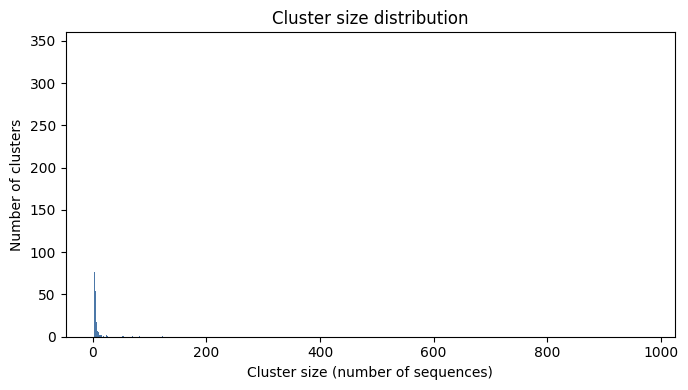

In [61]:
#histogram of cluster size

# clusters_df expected columns: cluster_id, size, members (optional)
print(f"Total clusters: {len(clusters_df)}")
size_counts = Counter(clusters_df['size'])
print("Cluster size distribution (size -> count):")
for s in sorted(size_counts):
    print(f"  {s}: {size_counts[s]}")


sizes = clusters_df['size'].tolist()
plt.figure(figsize=(7,4))
bins = range(1, (max(sizes) if sizes else 1) + 2)
plt.hist(sizes, bins=bins, color="#4c78a8")
plt.title("Cluster size distribution")
plt.xlabel("Cluster size (number of sequences)")
plt.ylabel("Number of clusters")
plt.tight_layout()
plt.show()


In [54]:
#sex-based degree distribution
# Assuming df_degrees has columns: node, degree, sex
# If not yet built:
degs = pd.concat([
    edges_df[['source']].rename(columns={'source':'node'}),
    edges_df[['target']].rename(columns={'target':'node'})
], axis=0)
degs = degs.groupby('node').size().reset_index(name='degree')

# Join sex from metadata (meta_df indexed by Sequence_ID)
deg_meta = degs.merge(meta_df[['Sequence_ID','sex']], left_on='node', right_on='Sequence_ID', how='left')
deg_meta['sex'] = deg_meta['sex'].fillna('Unknown').str.strip().str.capitalize()

# Summary table
print(deg_meta.groupby('sex')['degree'].agg(['count','mean','median','std']))

# Histogram side-by-side
import matplotlib.pyplot as plt
plt.figure(figsize=(9,4))
plt.subplot(1,2,1)
deg_meta[deg_meta['sex']=='Male']['degree'].plot(kind='hist', bins=30, color='#4c78a8', alpha=0.7)
plt.title("Degree distribution (Male)")
plt.xlabel("Degree")
plt.subplot(1,2,2)
deg_meta[deg_meta['sex']=='Female']['degree'].plot(kind='hist', bins=30, color='#f58518', alpha=0.7)
plt.title("Degree distribution (Female)")
plt.xlabel("Degree")
plt.tight_layout()
plt.show()


ValueError: 'Sequence_ID' is both an index level and a column label, which is ambiguous.

In [47]:

edges_df.to_csv(os.path.join(outdir, "edges.country.tsv"), sep="\t", index=False)
clusters_df.to_csv(os.path.join(outdir, "clusters.country.tsv"), sep="\t", index=False)

summary = {
    "total_sequences_with_dates": len(ids),
    "total_candidate_pairs": len(candidate_pairs),
    "total_edges": len(edges_df),
    "total_clusters": len(clusters_df),
    "cluster_size_distribution": dict(Counter([len(c) for c in clusters_sorted])),
}
pd.Series(summary).to_json(os.path.join(outdir, "summary.country.json"), indent=2)

print("Saved to:", outdir)


Saved to: network_analysis


In [48]:
## file paths and data loading

aln_path="data/8.final_filtered_sequences_exact_date.fasta"
meta_path="data/9.filter.xlsx"

##Read FASTA
fasta=read_fasta(aln_path)
seq_ids = [header for header, seq in fasta]
seq_map = {header: seq for header, seq in fasta}
print(f"Loaded {len(fasta)} aligned sequences.")


Loaded 5506 aligned sequences.


In [177]:
#Read metadata
meta=pd.read_excel(meta_path)
meta["date_parsed"]=meta["collection_date"].apply(parse_date_safe)
meta["sex_norm"]=meta["sex"].astype(str).str.strip().str.capitalize()
meta=meta.set_index("Sequence_ID")


#keep only sequences that have metadata
ids=[sid for sid in seq_ids if sid in meta.index]
missing_meta=sorted(set(seq_ids)-set(ids))
if missing_meta:
    print(f"WARNING: {len(missing_meta)} sequences missing metadata; ignoring them.")
print(f"Sequences with metadata: {len(ids)}")


##Sequence_ID	collection_date	Simulated_date	country	region	sex	exact_day
##OP605578.1	2022-07	2022-07-15				0
##PV424067.1	2022-05-24	2022-05-24				1


Sequences with metadata: 5506


# 1.Build candidate pairs by date window (fast pruning)

In [178]:

lut = np.zeros(256, dtype=np.uint8)
for ch, val in [('A',1),('C',2),('G',3),('T',4),('a',1),('c',2),('g',3),('t',4)]:
    lut[ord(ch)] = val
def seq_to_uint8(seq: str):
    buf = np.frombuffer(seq.encode('ascii'), dtype=np.uint8, count=len(seq))
    return lut[buf]
seq_u8 = {sid: seq_to_uint8(seq_map[sid]) for sid in ids}


In [179]:

DATE_THRESHOLD = 15  # days
# metadata_df must include Accession_ID and Geo_Location (from your earlier GFF parsing export)
# meta is your DataFrame with index=sequence_id and 'date_parsed' column.

# Ensure we have only sequences present in meta
metadata_filtered = metadata_df[metadata_df["Accession_ID"].isin(meta.index)].copy()

# Group by Geo_Location -> list of sequence IDs
ids_by_loc = (
    metadata_filtered[["Accession_ID", "Geo_Location"]]
    .dropna(subset=["Geo_Location"])
    .groupby("Geo_Location")["Accession_ID"]
    .apply(list)
    .to_dict()
)

candidate_pairs = []
for loc, loc_ids in ids_by_loc.items():
    # Keep only those with parsed dates
    loc_ids = [sid for sid in loc_ids if meta.at[sid, "date_parsed"] is not None]
    if not loc_ids:
        continue

    # Sort by date
    loc_ids_sorted = sorted(loc_ids, key=lambda x: meta.at[x, "date_parsed"])
    L = len(loc_ids_sorted)

    # Two-pointer window to add pairs within DATE_THRESHOLD days
    for i in range(L):
        di = meta.at[loc_ids_sorted[i], "date_parsed"]
        k = i + 1
        while k < L:
            dk = meta.at[loc_ids_sorted[k], "date_parsed"]
            if (dk - di).days <= DATE_THRESHOLD:
                candidate_pairs.append((loc_ids_sorted[i], loc_ids_sorted[k]))
                k += 1
            else:
                break



2. Multiprocessing edge computation (basic) ---

In [ ]:

# --- Multiprocessing edge computation (basic) ---

from multiprocessing import Pool, cpu_count

SNP_THRESHOLD   = 5
MIN_COMPARABLE  = 150_000

def compute_edge(pair):
    id1, id2 = pair
    u1 = seq_u8[id1]  # pre-encoded uint8 sequences (A/C/G/T=1..4, others=0)
    u2 = seq_u8[id2]
    diffs, comparable = snp_and_comparable(u1, u2)
    if comparable >= MIN_COMPARABLE and diffs <= SNP_THRESHOLD:
        d1 = meta.at[id1, "date_parsed"]
        d2 = meta.at[id2, "date_parsed"]
        day_diff = abs((d2 - d1).days)
        return {
            "source": id1,
            "target": id2,
            "snp_distance": diffs,
            "comparable_sites": comparable,
            "date_difference": day_diff
        }
    return None

# Tune chunksize: larger for smaller tasks to reduce IPC overhead (try 5000–20000)
chunksize = 5000

with Pool(processes=cpu_count()) as pool:
    results = pool.map(compute_edge, candidate_pairs, chunksize=chunksize)

edges = [r for r in results if r is not None]
edges_df = pd.DataFrame(edges)
print(f"[MP-basic] Built {len(edges_df)} edges from {len(candidate_pairs)} candidate pairs using {cpu_count()} processes.")
edges_df.head()


In [ ]:

# Cell: Vectorized SNP/comparable computation helpers

import numpy as np

# Map characters to small integers: A=1, C=2, G=3, T=4, others=0 (N, gaps, ambiguity)
# Using a 256-length lookup table for fast mapping from bytes
lut = np.zeros(256, dtype=np.uint8)
lut[ord('A')] = 1
lut[ord('C')] = 2
lut[ord('G')] = 3
lut[ord('T')] = 4
# Also uppercase guard (we already uppercased, but safe to include lowercase)
lut[ord('a')] = 1
lut[ord('c')] = 2
lut[ord('g')] = 3
lut[ord('t')] = 4

def seq_to_uint8(seq: str) -> np.ndarray:
    """Convert sequence string to uint8 codes via LUT (A=1,C=2,G=3,T=4, others=0)."""
    b = np.frombuffer(seq.encode('ascii'), dtype=np.uint8, count=len(seq))
    return lut[b]

# Pre-encode all sequences once
seq_u8 = {sid: seq_to_uint8(seq_map[sid]) for sid in ids}

def snp_and_comparable(u1: np.ndarray, u2: np.ndarray):
    """
    Vectorized SNP differences and comparable-site count.
    u1/u2 are uint8 arrays (A/C/G/T mapped to 1..4; others 0).
    Only positions where both are nonzero are comparable; SNP if values differ.
    """
    m = min(len(u1), len(u2))
    u1v = u1[:m]
    u2v = u2[:m]
    both = (u1v > 0) & (u2v > 0)
    comparable = int(both.sum())
    if comparable == 0:
        return 0, 0
    diffs = int((u1v[both] != u2v[both]).sum())
    return diffs, comparable


KeyboardInterrupt: 

In [ ]:

# Cell: Optional multiprocessing for candidate pairs
from multiprocessing import Pool, cpu_count

def compute_edge(args):
    id1, id2 = args
    u1 = seq_u8[id1]
    u2 = seq_u8[id2]
    diffs, comparable = snp_and_comparable(u1, u2)
    if comparable >= MIN_COMPARABLE and diffs <= SNP_THRESHOLD:
        d1 = meta.at[id1, "date_parsed"]
        d2 = meta.at[id2, "date_parsed"]
        day_diff = abs((d2 - d1).days)
        return {"source": id1, "target": id2, "snp_distance": diffs,
                "comparable_sites": comparable, "date_difference": day_diff}
    return None

with Pool(processes=cpu_count()) as pool:
    results = pool.map(compute_edge, candidate_pairs, chunksize=1000)

edges = [r for r in results if r is not None]
edges_df = pd.DataFrame(edges)
print(f"[MP] Built {len(edges_df)} edges among {len(ids)} sequences.")


In [113]:
#thresholds and edge building
SNP_THRESHOLD=5   #connect nodes with <= this SNP distance
DATE_THRESHOLD=15 #connect nodes with <= this many days difference
MIN_COMPARABLE=150_000 # require at least this many ACGT-overlap sites for an edge

edges = []
pairwise_dist = [] #for histgram/QC

for i, j in combinations(range(len(ids)),2):
    id1,id2=ids[i],ids[j]
    seq1, seq2=seq_map[id1], seq_map[id2]
    diffs, comparable=acgt_snp_distance(seq1, seq2)
    pairwise_dist.append(diffs)
    if comparable >= MIN_COMPARABLE and diffs <= SNP_THRESHOLD:
        date1, date2=meta.at[id1,"date_parsed"], meta.at[id2,"date_parsed"]
        day_diff=days_between(date1, date2)
        if day_diff is not None and day_diff <= DATE_THRESHOLD:
            edges.append({"source": id1, "target": id2, "snp_distance": diffs, "comparable_sites": comparable,"date_difference": day_diff,})
edges_df=pd.DataFrame(edges)
print(f"Built {len(edges_df)} edges among {len(ids)} sequences.")
edges_df.head()


KeyboardInterrupt: 

[(1, 2), (1, 3), (2, 3)]


In [30]:
##separate sequences based on country and sex

import os
import pandas as pd
from Bio import SeqIO

# Paths
input_fasta = "data/8.final_filtered_sequences_with_ref_NC.fasta"
output_dir = "data/separated_sequences/Region"
separate_file = "data/9.filter.xlsx"
os.makedirs(output_dir, exist_ok=True)

# Read sequences and metadata
records = list(SeqIO.parse(input_fasta, "fasta"))
df_separate = pd.read_excel(separate_file)

# Normalize IDs in metadata
Global_male = df_separate[df_separate['sex']=="male"]['Sequence_ID'].tolist()
Global_female = df_separate[df_separate['sex']=="female"]['Sequence_ID'].tolist()
USA= df_separate[(df_separate['country'] == 'USA')]['Sequence_ID'].tolist()
USA_male= df_separate[(df_separate['country'] == 'USA') & (df_separate['sex']=="male")]['Sequence_ID'].tolist()
USA_female= df_separate[(df_separate['country'] == 'USA') & (df_separate['sex']=="female")]['Sequence_ID'].tolist()
USA_California= df_separate[(df_separate['country'] == 'USA') & (df_separate['region']=="California")]['Sequence_ID'].tolist()
USA_Illinois= df_separate[(df_separate['country'] == 'USA') & (df_separate['region']=="Illinois")]['Sequence_ID'].tolist()
USA_New_York= df_separate[(df_separate['country'] == 'USA') & (df_separate['region']=="New York")]['Sequence_ID'].tolist()
USA_Washington= df_separate[(df_separate['country'] == 'USA') & (df_separate['region']=="Washington")]['Sequence_ID'].tolist()
Brazil= df_separate[(df_separate['country'] == 'Brazil')]['Sequence_ID'].tolist()
Brazil_male= df_separate[(df_separate['country'] == 'Brazil') & (df_separate['sex']=="male")]['Sequence_ID'].tolist()
Brazil_female=df_separate[(df_separate['country'] == 'Brazil') & (df_separate['sex']=="female")]['Sequence_ID'].tolist()
UK = df_separate[df_separate['country'] == 'UK']['Sequence_ID'].tolist()



# add ON676708.1 to all lists
for list_name in [Global_male, Global_female, USA, USA_male, USA_female, USA_California, USA_Illinois, USA_New_York, USA_Washington, Brazil, Brazil_male, Brazil_female, UK]:
    list_name.append("ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome")
    list_name.append("NC_063383")

 
print(f"sequence counts: {len(Global_male)}, {len(Global_female)}, {len(USA)}, {len(USA_male)}, {len(USA_female)}, {len(USA_California)}, {len(USA_Illinois)}, {len(USA_New_York)}, {len(USA_Washington)}, {len(Brazil)}, {len(Brazil_male)}, {len(Brazil_female)}, {len(UK)}")

# Generator for filtered records
def filtered_records_generator(keep_ids):
    for record in records:
        #print(record.id) # Debug: print each record ID
        normalized_id = record.id.split("|")[0].split(" ")[0]
        if normalized_id in keep_ids:
            yield record

# Output files
global_male_file = os.path.join(output_dir, "Global_male_sequences.fasta")
global_female_file = os.path.join(output_dir, "Global_female_sequences.fasta")
usa_file = os.path.join(output_dir, "USA_sequences.fasta")
usa_male_file = os.path.join(output_dir, "USA_male_sequences.fasta")
usa_female_file = os.path.join(output_dir, "USA_female_sequences.fasta")
usa_california_file = os.path.join(output_dir, "USA_California_sequences.fasta")
usa_illinois_file = os.path.join(output_dir, "USA_Illinois_sequences.fasta")
usa_newyork_file = os.path.join(output_dir, "USA_New_York_sequences.fasta")
usa_washington_file = os.path.join(output_dir, "USA_Washington_sequences.fasta")
brazil_file = os.path.join(output_dir, "Brazil_sequences.fasta")
brazil_male_file = os.path.join(output_dir, "Brazil_male_sequences.fasta")
brazil_female_file = os.path.join(output_dir, "Brazil_female_sequences.fasta")
uk_file = os.path.join(output_dir, "UK_sequences.fasta")


# Write sequences by filter
SeqIO.write(filtered_records_generator(Global_male), global_male_file, "fasta")
SeqIO.write(filtered_records_generator(Global_female), global_female_file, "fasta")
SeqIO.write(filtered_records_generator(USA), usa_file, "fasta")
SeqIO.write(filtered_records_generator(USA_male), usa_male_file, "fasta")
SeqIO.write(filtered_records_generator(USA_female), usa_female_file, "fasta")
SeqIO.write(filtered_records_generator(USA_California), usa_california_file, "fasta")
SeqIO.write(filtered_records_generator(USA_Illinois), usa_illinois_file, "fasta")
SeqIO.write(filtered_records_generator(USA_New_York), usa_newyork_file, "fasta")
SeqIO.write(filtered_records_generator(USA_Washington), usa_washington_file, "fasta")
SeqIO.write(filtered_records_generator(Brazil), brazil_file, "fasta")
SeqIO.write(filtered_records_generator(Brazil_male), brazil_male_file, "fasta")
SeqIO.write(filtered_records_generator(Brazil_female), brazil_female_file, "fasta")
SeqIO.write(filtered_records_generator(UK), uk_file, "fasta")



print("✅ Sequences separated and ON676708.1 and NC_063383 added to all files.")


sequence counts: 1600, 79, 5502, 230, 8, 1118, 189, 2264, 431, 310, 263, 38, 398
✅ Sequences separated and ON676708.1 and NC_063383 added to all files.


In [69]:
## check the first few records in the separated fasta files
separated_fasta="data/8.final_filtered_sequences_with_ref_NC.fasta"
check_count=5
for record in SeqIO.parse(separated_fasta, "fasta"):
    print(record.id)
    check_count -= 1
    if check_count == 0:
        break



NC_063383
ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome
hMpxV/Switzerland/ZH-UZH-IMV-3ba6450e/2022|EPI_ISL_13251584|2022-06-02
hMpxV/Germany/un-RKI-013/2022|EPI_ISL_13308117|2022-06
hMpxV/Germany/un-RKI-026/2022|EPI_ISL_13308118|2022-06


In [76]:
a="NC_063383,ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome"
excluded_sequences = {x.strip() for x in a.split(",") if x.strip()}

In [86]:
if " a".strip()==True:
    print("yes")

In [100]:
#check the mapping

reference_file = "data/separated_sequences/Region/reference_sequence.fasta"
alignment_file = "data/separated_sequences/Region/USA_male_female_sequences.fasta"

# Read reference

problem_positions = [3111, 39139]  # Add more positions if needed

# Read reference sequence
reference_seq = "".join([str(record.seq) for record in SeqIO.parse(reference_file, "fasta")])

# Read alignment (first sequence for mapping)
alignment_seq = str(next(SeqIO.parse(alignment_file, "fasta")).seq)

# Build mapping: alignment index -> reference index
position_translation = {}
ref_index = 0
for aln_index, base in enumerate(alignment_seq, start=1):
    if base != "-":  # skip gaps
        ref_index += 1
        position_translation[aln_index] = ref_index

# Check problematic positions
print(f"Reference length: {len(reference_seq)}")
print(f"Alignment length: {len(alignment_seq)}\n")
print("Check results:")
for pos in problem_positions:
    if pos in position_translation:
        print(f"Position {pos}: mapped to reference position {position_translation[pos]}")
    else:
        print(f"Position {pos}: MISSING (likely gap or insertion)")



Reference length: 197173
Alignment length: 197209

Check results:
Position 3111: mapped to reference position 3111
Position 39139: mapped to reference position 39139


In [110]:

# Replace with your FASTA file path
fasta_file = "data/separated_sequences/Region/Brazil_male_female_sequences.fasta"

# Read sequences
sequences = list(SeqIO.parse(fasta_file, "fasta"))

# Collect lengths and gap counts
lengths = [len(str(seq.seq)) for seq in sequences]
gap_counts = [str(seq.seq).count('-') for seq in sequences]

# Check alignment consistency
unique_lengths = set(lengths)

print(f"Total sequences: {len(sequences)}")
print(f"Unique sequence lengths: {unique_lengths}")

if len(unique_lengths) == 1:
    print("✅ All sequences have the same length. Likely aligned.")
else:
    print("⚠ Sequences have different lengths. Not properly aligned.")

# Detailed report
print("\nDetailed report:")
for i, record in enumerate(sequences):
    print(f"{record.id}: length={lengths[i]}, gaps={gap_counts[i]}")


Total sequences: 263
Unique sequence lengths: {197209}
✅ All sequences have the same length. Likely aligned.

Detailed report:
ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome: length=197209, gaps=10
hMpxV/Brazil/PR-IAL-54/2022|EPI_ISL_14625230|2022-08-03: length=197209, gaps=10
hMpxV/Brazil/SP-IAL-56/2022|EPI_ISL_14625282|2022-08-08: length=197209, gaps=10
hMpxV/Brazil/RS-IAL-02/2022|EPI_ISL_13234112|2022-05-31: length=197209, gaps=10
hMpxV/Brazil/RS-IAL-40/2022|EPI_ISL_14622913|2022-07-26: length=197209, gaps=10
hMpxV/Brazil/RS-IAL-41/2022|EPI_ISL_14622953|2022-07-29: length=197209, gaps=10
hMpxV/Brazil/SP-IAL-42/2022|EPI_ISL_14622960|2022-07-31: length=197209, gaps=10
hMpxV/Brazil/SP-IAL-53/2022|EPI_ISL_14625190|2022-08-05: length=197209, gaps=10
hMpxV/Brazil/PR-IAL-55/2022|EPI_ISL_14625256|2022-08-05: length=197209, gaps=10
hMpxV/Brazil/SP-IAL-03/2022|EPI_ISL_13314740|2022-06-11: length=197209, gaps=10
hMpxV/Brazil/SP-IAL-23/2022|EPI_ISL_14070852|2022-07-19: len

In [112]:
# Replace with your FASTA file path
# fasta_file = "data/separated_sequences/Region/Brazil_male_female_sequences.fasta"
# 

# Update these paths
reference_file = "data/separated_sequences/Region/Brazil_male_female_sequences.fasta"
vcf_file = "data/separated_sequences/Region/Brazil_male_female_sequences.vcf"

# Load reference sequence
reference_seq = "".join([str(record.seq) for record in SeqIO.parse(reference_file, "fasta")])

errors = []
with open(vcf_file) as f:
    for line in f:
        if line.startswith("#"):
            continue
        chrom, pos, vid, ref, alt, *_ = line.strip().split("\t")
        pos = int(pos)
        if pos > len(reference_seq):
            errors.append(f"Position {pos} out of range (reference length {len(reference_seq)})")
        else:
            ref_base = reference_seq[pos - 1]  # VCF positions are 1-based
            if ref_base != ref:
                errors.append(f"REF mismatch at {pos}: VCF={ref}, Reference={ref_base}")

# Report results
if errors:
    print("⚠ Found mismatches:")
    for e in errors[:50]:  # Show first 50
        print(e)
else:
    print("✅ All REF bases match the reference.")


✅ All REF bases match the reference.


In [55]:
on676708_record

In [65]:
#check the first record in the new fasta file

# Input FASTA file
fasta_file = "data/separated_sequences/Region/USA_female_sequences.fasta"
position = 71777  # SNP position
window = 1      # Number of bases before and after

# Load sequences
for record in SeqIO.parse(fasta_file, "fasta"):
    seq_id = record.id
    seq = record.seq
    start = max(0, position - window - 1)  # Python index
    end = min(len(seq), position + window)
    snippet = seq[start:end]
    center_base = seq[position - 1]
    print(f">{seq_id} | Position {position} | Base: {center_base}")
    print(snippet)

    

>NC_063383 | Position 71777 | Base: G
TGA
>ON676708.1_Monkeypox_virus_isolate_MPXV_USA_2021_MD__complete_genome | Position 71777 | Base: G
TGA
>hMpxV/USA/TX-DCHHS-0021/2022|EPI_ISL_18723958|2022-08-09 | Position 71777 | Base: G
TGA
>hMpxV/USA/TX-DCHHS-0123/2022|EPI_ISL_18746992|2022-09-22 | Position 71777 | Base: G
TGA
>hMpxV/USA/TX-DCHHS-0088/2022|EPI_ISL_18746995|2022-09-02 | Position 71777 | Base: G
TGA
>hMpxV/USA/TX-DCHHS-0080/2022|EPI_ISL_18737444|2022-08-31 | Position 71777 | Base: A
TAA
